# Business Information Systems Exam Project · Patient Treatment in Brazilian HR 

## Intro

Starting from a brazilian hospital dataset, we want to observe some aspects on how is the flow working and achieve some knowledge about it, especially:

1. **efficient patient flow**: in order to minimize the waiting time for patients and try to improve the overall experience of the hospital,
2. **analyze process**: find structural inefficiencies and assess conformance,
3. **propose improvements**

In [ ]:
import os, warnings
os.environ["PM4PY_SHOW_PROGRESS_BAR"] = "False"    

import numpy as np
import pandas as pd
import contextlib, io
with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()): 
    import sys
    sys.path.insert(0, r"C:\pylibs")

import pm4py
print('PM4Py:', pm4py.__version__)

import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="IProgress not found")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)

import scipy.stats as stats

PM4Py: 2.7.23.8


### 0 · The event log

The event log is structured as a standard XES-compliant CSV file.

Every event log has a minimum of three mandatory information for every event that is represented inside the CSV file has a row and in this specific case we have:

1. **ID** --> the Patient ID in the file can be found inside the column `case:concept:name`
2. **ACTIVITY** --> determines the process flow, determined by `concept:name`
3. **TIMESTAMP** --> releted to the moment in time when an activity occured, spicified as `time:timestamp`

There are also other columns were there are specified some attributes that can be useful in order to achieve some knowledge that can lead us; for example there are *Item* column that gives details on what materials or medications used during the treatment and *Medico responsavel* that is the coulmn related to the resource.

In [36]:
LOG_PATH = "UpFLux_Healthcare_Database_labeled.csv"      # Hospital log


# Make sure types are right: dates as dates, measurements as numbers
log["time:timestamp"] = pd.to_datetime(log["time:timestamp"], utc=True)
log["case:concept:name"] = log["case:concept:name"].astype(str)
for column in ["Idade"]:
    log[column] = pd.to_numeric(log[column], errors="coerce")

n_missing_timestamps = log["time:timestamp"].isna().sum()
log = log.dropna(subset=["time:timestamp"]).copy()
print(f"Events removed because timestamp is missing: {n_missing_timestamps}")

# Events of one case in time order (a stable sort keeps simultaneous events in file order)
log = log.sort_values(["case:concept:name", "time:timestamp"], kind="stable")
n_cases = log["case:concept:name"].nunique()

print("\nDataset structure:")
log.info()

print("\nMissing values per column (reported only):")
print(log.isna().sum())

print("\nEvents by activity:")
print(log["concept:name"].value_counts(dropna=False))


Events removed because timestamp is missing: 0

Dataset structure:
<class 'pandas.DataFrame'>
Index: 3075 entries, 0 to 3092
Data columns (total 19 columns):
 #   Column              Non-Null Count  Dtype              
---  ------              --------------  -----              
 0   case:concept:name   3075 non-null   str                
 1   Idade               3075 non-null   int64              
 2   Sexo                3075 non-null   str                
 3   Nível de Urgência   3075 non-null   str                
 4   CID                 3075 non-null   str                
 5   Médico Responsável  3075 non-null   str                
 6   Doença              3075 non-null   str                
 7   Data Inicial        3075 non-null   str                
 8   time:timestamp      3075 non-null   datetime64[us, UTC]
 9   concept:name        3075 non-null   str                
 10  Item                3075 non-null   str                
 11  Data Prescrição     377 non-null    str     

In [37]:
n_cases = log["case:concept:name"].nunique()
print(f"Events: {len(log)}   Cases: {n_cases}")
print(f"Distinct variants: {len(pm4py.get_variants(log))}")
print("Start activities:", pm4py.get_start_activities(log))
print("End activities:  ", pm4py.get_end_activities(log))

Events: 3075   Cases: 443
Distinct variants: 111
Start activities: {'Atendimento': 443}
End activities:   {'Alta': 436, 'Exames Laboratoriais': 3, 'Exames Eletrofisiológicos': 2, 'Exames de Imagem': 2}


Cases: 443; exact variants: 111
Variants occurring once: 94 (84.7% of variants)
Cases in those variants: 94 (21.2% of cases)
Top 1 variants cover 247/443 cases (55.8%)
Top 5 variants cover 320/443 cases (72.2%)
Top 10 variants cover 335/443 cases (75.6%)


,variant,path,cases,share_%,cumulative_%
0,V001,Atendimento → Triagem → Consulta → Alta,247,55.8,55.8
1,V002,Atendimento → Triagem → Consulta → Exames de Imagem → Alta,49,11.1,66.8
2,V003,Atendimento → Triagem → Consulta → Exames Laboratoriais → Alta,12,2.7,69.5
3,V004,Atendimento → Triagem → Consulta → Exames Laboratoriais → Exames Laboratoriais → Exames de Imagem → Alta,8,1.8,71.3
4,V005,Atendimento → Triagem → Consulta → Exames Laboratoriais → Exames de Imagem → Alta,4,0.9,72.2
5,V006,Atendimento → Triagem → Consulta → Materiais Hospitalares → Materiais Hospitalares → Materiais Hospitalares → Materi...,4,0.9,73.1
6,V007,Atendimento → Consulta → Exames Laboratoriais → Alta,3,0.7,73.8
7,V008,Atendimento → Triagem → Consulta → Medicamentos → Alta,3,0.7,74.5
8,V009,Atendimento → Consulta → Alta,3,0.7,75.2
9,V010,Atendimento → Triagem → Exames Laboratoriais → Consulta → Alta,2,0.5,75.6


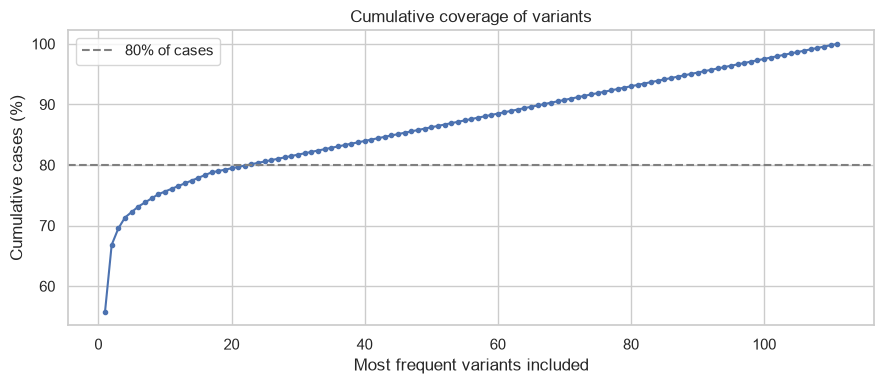

In [50]:
variant_counts = log.groupby("case:concept:name", sort=False)["concept:name"].agg(tuple).value_counts()
total_cases = int(variant_counts.sum())

variant_distribution = pd.DataFrame({
    "variant": [f"V{i:03}" for i in range(1, len(variant_counts) + 1)],
    "path": [" → ".join(activities) for activities in variant_counts.index],
    "cases": variant_counts.to_numpy(),
})
variant_distribution["share_%"] = variant_distribution["cases"] / total_cases * 100
variant_distribution["cumulative_%"] = variant_distribution["share_%"].cumsum()

single_case_variants = int((variant_counts == 1).sum())
cases_in_single_case_variants = int(variant_counts[variant_counts == 1].sum())
print(f"Cases: {total_cases}; exact variants: {len(variant_counts)}")
print(f"Variants occurring once: {single_case_variants} ({single_case_variants / len(variant_counts) * 100:.1f}% of variants)")
print(f"Cases in those variants: {cases_in_single_case_variants} ({cases_in_single_case_variants / total_cases * 100:.1f}% of cases)")
for n in (1, 5, 10):
    covered = int(variant_counts.head(n).sum())
    print(f"Top {n} variants cover {covered}/{total_cases} cases ({covered / total_cases * 100:.1f}%)")

display(variant_distribution.head(20).round({"share_%": 1, "cumulative_%": 1}))

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(range(1, len(variant_distribution) + 1), variant_distribution["cumulative_%"], marker=".")
ax.axhline(80, color="gray", linestyle="--", label="80% of cases")
ax.set(xlabel="Most frequent variants included", ylabel="Cumulative cases (%)", title="Cumulative coverage of variants")
ax.legend()
plt.tight_layout()
plt.show()

## 1 · Discovery without domain knowledge

### Judging the raw event log

Discovering a Petri net with the **inductive miner**; we keep a *noise threshold*, from 0 to 1, that tells how much infrequent behaviour to ignore; in this case we put it at 0.2, leveraing the differences that are coming from datas. Each model is scored on the log it was discovered from:

* **fitness**: how much of the log the model can replay ,
* **precision**: how little extra behaviour the model allows,
* **F1**: relationship between fitness and precision,
* **size**: number of transitions.


In [ ]:
def quality(log, tot_log, noise=0.2):
    net, im, fm = pm4py.discover_petri_net_inductive(log, noise_threshold=noise)
    fitness = pm4py.fitness_token_based_replay(tot_log, net, im, fm)["log_fitness"]
    precision = pm4py.precision_token_based_replay(tot_log, net, im, fm)
    activities = {t.label for t in net.transitions if t.label}
    row = {
        "cases": log["case:concept:name"].nunique(),
        "% of raw cases": round(100 * log["case:concept:name"].nunique() / n_cases, 1),
        "model transitions": len(net.transitions),
        "activities in model": len(activities),
        "fitness": round(fitness, 3),
        "precision": round(precision, 3),
        "F1": round(2 * fitness * precision / (fitness + precision), 3),
    }
    return row, (net, im, fm)

results = {}      # one row per model we build
models = {}     

### Baseline: discover from the raw log

In [48]:
import os
import shutil

os.environ["PATH"] = r"C:\Program Files\Graphviz\bin" + os.pathsep + os.environ.get("PATH", "")
dot_path = shutil.which("dot")
if dot_path is None:
    raise FileNotFoundError("Graphviz dot.exe was not found in C:\\Program Files\\Graphviz\\bin")

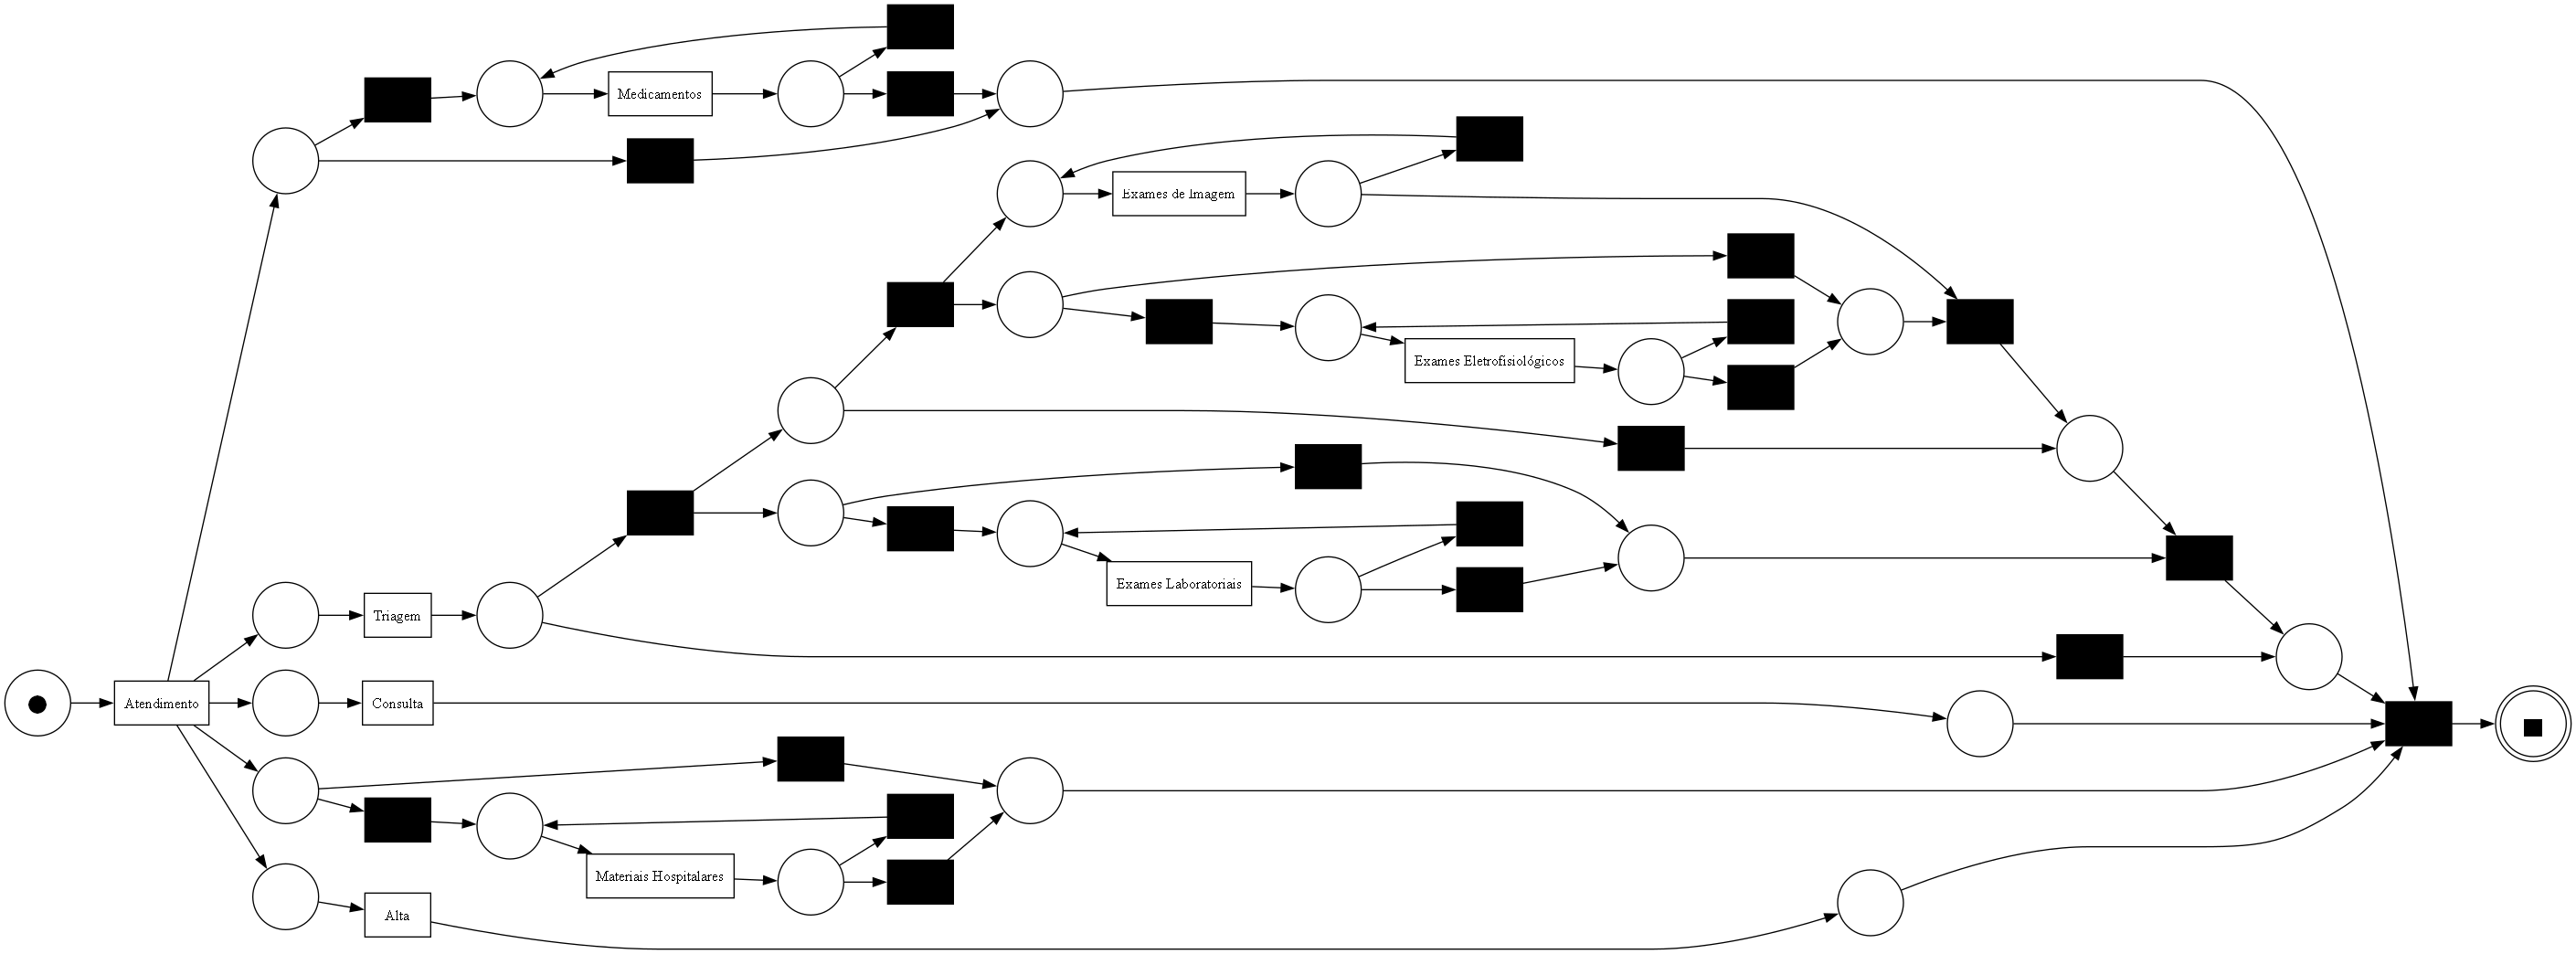

,cases,% of raw cases,model transitions,activities in model,fitness,precision,F1
raw log,443.0,100.0,33.0,9.0,0.988,0.547,0.705


In [49]:
results["raw log"], models["raw log"] = quality(log, log)
pm4py.view_petri_net(*models["raw log"], format="png")
pd.DataFrame(results).T

## 2 · Remove noise and irrelevant data

### Noise: incomplete cases

In [ ]:

log_clean = log.copy()

negative_quantity = log_clean["Quantidade"] < 0
negative_rows_removed = int(negative_quantity.sum())
log_clean = log_clean.loc[~negative_quantity].copy()

duplicate_rows_removed = int(log_clean.duplicated().sum())
log_clean = log_clean.drop_duplicates(keep="first").copy()

assert not (log_clean["Quantidade"] < 0).any()
assert not log_clean.duplicated().any()

print(f"Events removed for negative quantity: {negative_rows_removed}")
print(f"Exact duplicate rows removed: {duplicate_rows_removed}")
print(f"Clean events: {len(log_clean)} (before: {len(log)})")
print(f"Cases retained: {log_clean['case:concept:name'].nunique()} (before: {log['case:concept:name'].nunique()})")

Events removed for negative quantity: 17
Exact duplicate rows removed: 4
Clean events: 3054 (before: 3075)
Cases retained: 443 (before: 443)


In [ ]:
case_column = "case:concept:name"

negative_case_ids = set(log.loc[log["Quantidade"] < 0, case_column])
duplicate_case_ids = set(log.loc[log.duplicated(keep=False), case_column])
excluded_case_ids = negative_case_ids | duplicate_case_ids

log_clean_no_flagged_cases = log_clean.loc[
    ~log_clean[case_column].isin(excluded_case_ids)
].copy()

assert not log_clean_no_flagged_cases[case_column].isin(excluded_case_ids).any()
assert not (log_clean_no_flagged_cases["Quantidade"] < 0).any()
assert not log_clean_no_flagged_cases.duplicated().any()

print(f"Cases with negative quantities: {len(negative_case_ids)}")
print(f"Cases with exact duplicate rows: {len(duplicate_case_ids)}")
print(f"Cases flagged in both groups: {len(negative_case_ids & duplicate_case_ids)}")
print(f"Total cases excluded: {len(excluded_case_ids)}")
print(f"log_clean: {len(log_clean)} events, {log_clean[case_column].nunique()} cases")
print(f"log_clean_no_flagged_cases: {len(log_clean_no_flagged_cases)} events, {log_clean_no_flagged_cases[case_column].nunique()} cases")

Cases with negative quantities: 9
Cases with exact duplicate rows: 3
Cases flagged in both groups: 1
Total cases excluded: 11
log_clean: 3054 events, 443 cases
log_clean_no_flagged_cases: 2783 events, 432 cases


## 3 · Log segmentation

### Segmentation by Doenca attribute

In [ ]:
# Segment the event log by the case-level diagnosis (Doença).
# Use the alternative cleaned log so cases flagged for data-quality issues are excluded.
base_log = log_clean_no_flagged_cases
case_column = "case:concept:name"
activity_column = "concept:name"
disease_column = "Doença"

# A partition is only valid if each case has exactly one diagnosis.
diseases_per_case = base_log.groupby(case_column)[disease_column].nunique(dropna=False)
if not diseases_per_case.eq(1).all():
    raise ValueError("Each case must have exactly one Doença value for disease-based segmentation.")


disease_per_case = base_log.groupby(case_column, sort=False)[disease_column].first()
log_segments_by_disease = {
    disease: base_log.loc[
        base_log[case_column].isin(disease_per_case.index[disease_per_case == disease])
    ].copy()
    for disease in disease_per_case.value_counts().index
}

case_summary = base_log.groupby(case_column).agg(
    disease=(disease_column, "first"),
    n_events=(activity_column, "size"),
    start=("time:timestamp", "min"),
    end=("time:timestamp", "max"),
)
case_summary["duration_hours"] = (
    case_summary["end"] - case_summary["start"]
).dt.total_seconds() / 3600

summary_rows = []
for disease, segment in log_segments_by_disease.items():
    case_ids = disease_per_case.index[disease_per_case == disease]
    variant_counts = segment.groupby(case_column, sort=False)[activity_column].agg(tuple).value_counts()
    segment_cases = case_summary.loc[case_ids]
    summary_rows.append({
        "Doença": disease,
        "cases": len(case_ids),
        "events": len(segment),
        "share_cases_%": len(case_ids) / base_log[case_column].nunique() * 100,
        "distinct_variants": len(variant_counts),
        "top_variant_cases": int(variant_counts.iloc[0]),
        "top_variant_share_%": variant_counts.iloc[0] / len(case_ids) * 100,
        "median_events_per_case": segment_cases["n_events"].median(),
        "median_duration_hours": segment_cases["duration_hours"].median(),
    })

segment_summary = pd.DataFrame(summary_rows).sort_values(
    "cases", ascending=False
).reset_index(drop=True)

# Check that segments are disjoint and together retain every case and event.
assert sum(len(segment) for segment in log_segments_by_disease.values()) == len(base_log)
assert sum(segment[case_column].nunique() for segment in log_segments_by_disease.values()) == base_log[case_column].nunique()

print(f"Base log: {len(base_log)} events, {base_log[case_column].nunique()} cases")
print(f"Number of disease segments: {len(log_segments_by_disease)}")
display(segment_summary.round({"share_cases_%": 1, "top_variant_share_%": 1, "median_duration_hours": 2}))

Base log: 2783 events, 432 cases
Number of disease segments: 6


,Doença,cases,events,share_cases_%,distinct_variants,top_variant_cases,top_variant_share_%,median_events_per_case,median_duration_hours
0,J11.1 Influenza c/out manif resp dev virus n ident,347,1694,80.3,42,240,69.2,4.0,1.18
1,N23 Colica nefretica NE,43,633,10.0,40,3,7.0,15.0,2.83
2,R07.4 Dor toracica NE,30,306,6.9,21,6,20.0,8.0,2.13
3,R07.3 Outr dor toracica,5,29,1.2,3,3,60.0,5.0,2.48
4,I64 Acid vasc cerebr NE como hemorrag isquemico,4,93,0.9,4,1,25.0,28.0,2.55
5,J12.9 Pneumonia viral NE,3,28,0.7,3,1,33.3,7.0,2.20


First of all, there is a clear separation between the segments, this leads at the conclusion that there is no overlapping, so a comparison is legit.  Second, from the table below it is clear that the top 3 segments includes almost the totality of the filtered event log.

In [57]:
# Focus the main comparison on the three most frequent diagnoses.
main_diseases = segment_summary.head(3)["Doença"].tolist()
main_disease_segments = {
    disease: log_segments_by_disease[disease]
    for disease in main_diseases
}
rare_disease_segments = {
    disease: segment
    for disease, segment in log_segments_by_disease.items()
    if disease not in main_diseases
}

# Combined main log is convenient for later comparisons; original segments remain available.
log_main_diseases = pd.concat(main_disease_segments.values()).sort_values(
    [case_column, "time:timestamp"], kind="stable"
).copy()

main_case_count = log_main_diseases[case_column].nunique()
main_event_count = len(log_main_diseases)
total_case_count = base_log[case_column].nunique()
total_event_count = len(base_log)
rare_case_count = sum(segment[case_column].nunique() for segment in rare_disease_segments.values())
rare_event_count = sum(len(segment) for segment in rare_disease_segments.values())

assert main_case_count + rare_case_count == total_case_count
assert main_event_count + rare_event_count == total_event_count

print(f"Main analysis: {main_case_count}/{total_case_count} cases ({main_case_count / total_case_count:.1%}), "
      f"{main_event_count}/{total_event_count} events ({main_event_count / total_event_count:.1%})")
print("Rare diagnoses are retained separately for descriptive/exploratory analysis:")
display(segment_summary[segment_summary["Doença"].isin(main_diseases)].reset_index(drop=True))

Main analysis: 420/432 cases (97.2%), 2633/2783 events (94.6%)
Rare diagnoses are retained separately for descriptive/exploratory analysis:


,Doença,cases,events,share_cases_%,distinct_variants,top_variant_cases,top_variant_share_%,median_events_per_case,median_duration_hours
0,J11.1 Influenza c/out manif resp dev virus n ident,347,1694,80.324074,42,240,69.164265,4.0,1.183333
1,N23 Colica nefretica NE,43,633,9.953704,40,3,6.976744,15.0,2.833333
2,R07.4 Dor toracica NE,30,306,6.944444,21,6,20.000000,8.0,2.133333


## 4 - Comparison between segments
### Preparing datas:
    -  Build one row per case for the three selected diagnosis segments.
    -  Count repeated consultations, lab tests, and imaging beyond the first occurrence.
    -  Holm adjustement function

In [ ]:

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
from IPython.display import display

comparison_log = log_main_diseases.copy()
comparison_cases = comparison_log.groupby(case_column).agg(
    disease=(disease_column, "first"),
    case_events=(activity_column, "size"),
    distinct_activities=(activity_column, "nunique"),
    first_event=("time:timestamp", "min"),
    last_event=("time:timestamp", "max"),
)
comparison_cases["duration_hours"] = (
    comparison_cases["last_event"] - comparison_cases["first_event"]
).dt.total_seconds() / 3600


activity_counts = comparison_log.groupby([case_column, activity_column]).size().unstack(fill_value=0)
procedure_activities = {
    "Consulta": "repeat_consultations",
    "Exames Laboratoriais": "repeat_lab_tests",
    "Exames de Imagem": "repeat_imaging_tests",
}
for activity, metric in procedure_activities.items():
    counts = (
        activity_counts[activity]
        if activity in activity_counts.columns
        else pd.Series(0, index=comparison_cases.index)
    )
    comparison_cases[metric] = (
        counts.reindex(comparison_cases.index, fill_value=0) - 1
    ).clip(lower=0)

comparison_cases["repeated_procedures"] = comparison_cases[
    list(procedure_activities.values())
].sum(axis=1)
if comparison_cases.empty:
    raise ValueError("No cases are available in the selected diagnosis segments.")

def holm_adjust(p_values):
    p_values = np.asarray(p_values, dtype=float)
    order = np.argsort(p_values)
    adjusted = np.empty(len(p_values), dtype=float)
    running_max = 0.0
    for rank, index in enumerate(order):
        running_max = max(running_max, (len(p_values) - rank) * p_values[index])
        adjusted[index] = min(running_max, 1.0)
    return adjusted

### First analysis:
compare *duration* with case properties inside each diagnosis segment.

In [ ]:


required_columns = {"disease", "duration_hours", "case_events", "repeated_procedures"}
missing_columns = required_columns - set(comparison_cases.columns)
if missing_columns:
    raise KeyError(f"Missing case-level metrics: {sorted(missing_columns)}")

case_property_analysis = comparison_cases.copy()
case_property_analysis["has_rework"] = case_property_analysis["repeated_procedures"] > 0

print("Case properties by diagnosis (duration is the observed event-log span):")
case_property_summary = case_property_analysis.groupby("disease", sort=False).agg(
    cases=("case_events", "size"),
    duration_median_h=("duration_hours", "median"),
    duration_q1_h=("duration_hours", lambda values: values.quantile(0.25)),
    duration_q3_h=("duration_hours", lambda values: values.quantile(0.75)),
    case_size_median=("case_events", "median"),
    case_size_q1=("case_events", lambda values: values.quantile(0.25)),
    case_size_q3=("case_events", lambda values: values.quantile(0.75)),
    cases_with_rework=("has_rework", "sum"),
).reset_index()
case_property_summary["rework_rate_%"] = (
    100 * case_property_summary["cases_with_rework"] / case_property_summary["cases"]
)
display(case_property_summary.round(2))



Case properties by diagnosis (duration is the observed event-log span, not administrative LOS):


,disease,cases,duration_median_h,duration_q1_h,duration_q3_h,case_size_median,case_size_q1,case_size_q3,cases_with_rework,rework_rate_%
0,J11.1 Influenza c/out manif resp dev virus n ident,347,1.18,0.67,2.05,4.0,4.0,5.00,15,4.32
1,R07.4 Dor toracica NE,30,2.13,1.14,5.62,8.0,5.0,14.75,8,26.67
2,N23 Colica nefretica NE,43,2.83,2.12,3.88,15.0,13.0,16.00,12,27.91


### Second analysis:
Is a *larger case* associated with a *longer* observed *duration* within each diagnosis?

In [ ]:

size_duration_rows = []
for disease, group in case_property_analysis.groupby("disease", sort=False):
    rho, p_value = stats.spearmanr(group["case_events"], group["duration_hours"])
    size_duration_rows.append({
        "disease": disease,
        "cases": len(group),
        "spearman_rho": rho,
        "p_raw": p_value,
    })
size_duration_tests = pd.DataFrame(size_duration_rows)
valid_size_tests = size_duration_tests["p_raw"].notna()
size_duration_tests["p_holm"] = np.nan
if valid_size_tests.any():
    size_duration_tests.loc[valid_size_tests, "p_holm"] = holm_adjust(
        size_duration_tests.loc[valid_size_tests, "p_raw"]
    )
print("Spearman association between case size (events) and duration, tested within each diagnosis:")
display(size_duration_tests.round(4))


Spearman association between case size (events) and duration, tested within each diagnosis:


,disease,cases,spearman_rho,p_raw,p_holm
0,J11.1 Influenza c/out manif resp dev virus n ident,347,0.4766,0.0000,0.0000
1,R07.4 Dor toracica NE,30,0.6220,0.0002,0.0005
2,N23 Colica nefretica NE,43,0.3277,0.0319,0.0319


### Third analysis
Does the presence of repeated consultations/tests/imaging coincide with longer duration?
If *Delta* is positive that means *rework cases* tend to *last longer*.

In [ ]:

rework_duration_rows = []
for disease, group in case_property_analysis.groupby("disease", sort=False):
    rework_hours = group.loc[group["has_rework"], "duration_hours"].to_numpy()
    no_rework_hours = group.loc[~group["has_rework"], "duration_hours"].to_numpy()
    row = {
        "disease": disease,
        "rework_cases": len(rework_hours),
        "no_rework_cases": len(no_rework_hours),
        "rework_median_h": np.median(rework_hours) if len(rework_hours) else np.nan,
        "no_rework_median_h": np.median(no_rework_hours) if len(no_rework_hours) else np.nan,
        "median_gap_h (rework - no rework)": (
            np.median(rework_hours) - np.median(no_rework_hours)
            if len(rework_hours) and len(no_rework_hours) else np.nan
        ),
        "cliffs_delta": np.nan,
        "p_raw": np.nan,
    }
    if len(rework_hours) and len(no_rework_hours):
        result = stats.mannwhitneyu(
            rework_hours, no_rework_hours, alternative="two-sided", method="auto"
        )
        row["p_raw"] = result.pvalue
        row["cliffs_delta"] = (
            np.count_nonzero(rework_hours[:, None] > no_rework_hours[None, :])
            - np.count_nonzero(rework_hours[:, None] < no_rework_hours[None, :])
        ) / (len(rework_hours) * len(no_rework_hours))
    rework_duration_rows.append(row)

rework_duration_tests = pd.DataFrame(rework_duration_rows)
valid_rework_tests = rework_duration_tests["p_raw"].notna()
rework_duration_tests["p_holm"] = np.nan
if valid_rework_tests.any():
    rework_duration_tests.loc[valid_rework_tests, "p_holm"] = holm_adjust(
        rework_duration_tests.loc[valid_rework_tests, "p_raw"]
    )
print("Duration by rework presence, compared within each diagnosis (Mann–Whitney; Holm-adjusted p-values):")
display(rework_duration_tests.round(4))


Duration by rework presence, compared within each diagnosis (Mann–Whitney; Holm-adjusted p-values):


,disease,rework_cases,no_rework_cases,rework_median_h,no_rework_median_h,median_gap_h (rework - no rework),cliffs_delta,p_raw,p_holm
0,J11.1 Influenza c/out manif resp dev virus n ident,15,332,3.1667,1.1083,2.0583,0.7863,0.0000,0.0000
1,R07.4 Dor toracica NE,8,22,5.8500,1.4917,4.3583,0.6875,0.0049,0.0098
2,N23 Colica nefretica NE,12,31,3.4167,2.5667,0.8500,0.4409,0.0273,0.0273


### Visual comparison
duration by rework and case size versus duration, separately by diagnosis.

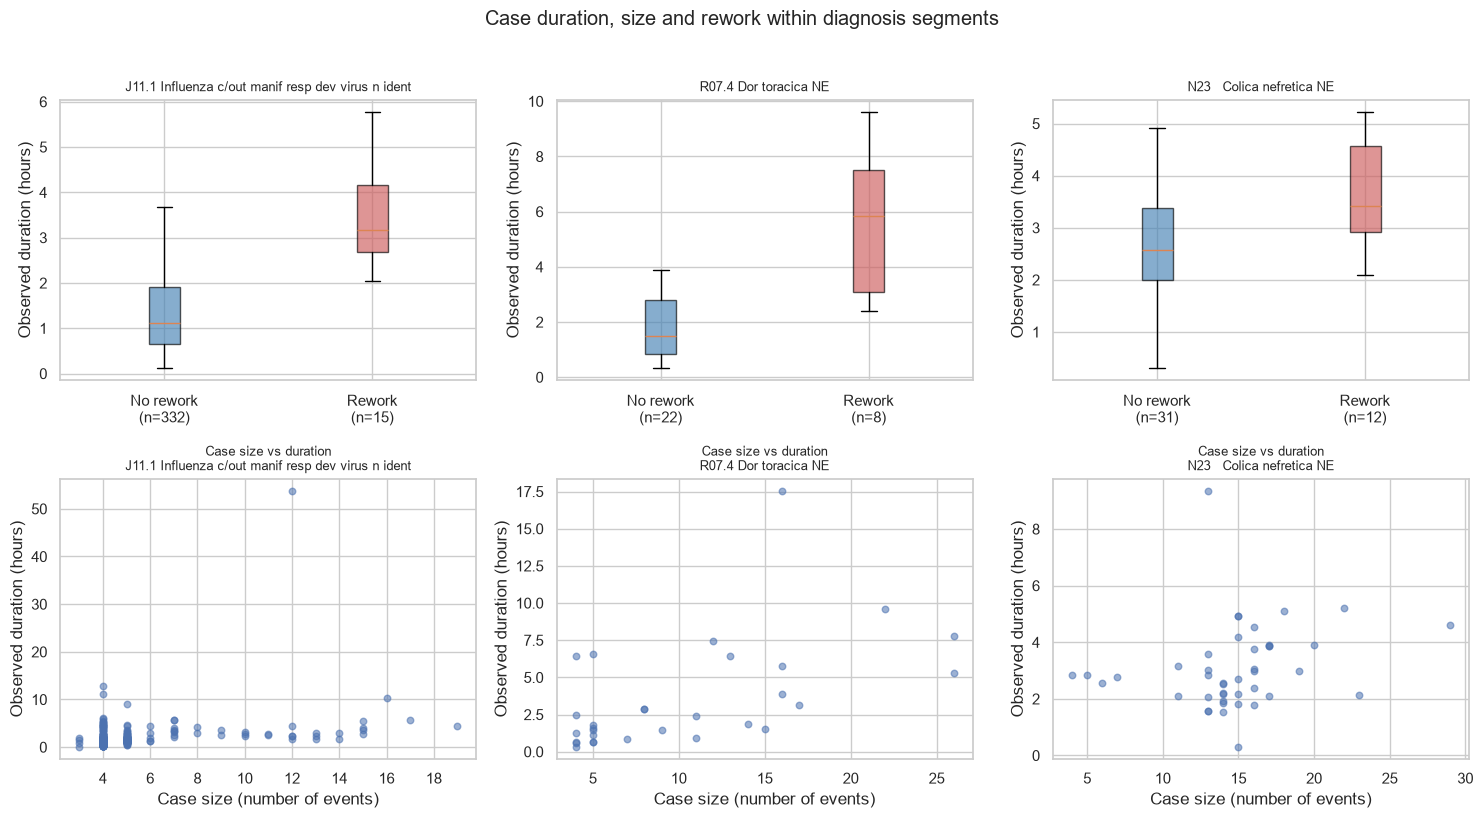

In [84]:

diseases = case_property_analysis["disease"].drop_duplicates().tolist()
fig, axes = plt.subplots(2, len(diseases), figsize=(5 * len(diseases), 8), squeeze=False)
for column_index, disease in enumerate(diseases):
    group = case_property_analysis[case_property_analysis["disease"] == disease]
    no_rework = group.loc[~group["has_rework"], "duration_hours"]
    rework = group.loc[group["has_rework"], "duration_hours"]
    ax = axes[0, column_index]
    box = ax.boxplot([no_rework, rework], showfliers=False, patch_artist=True)
    for patch, color in zip(box["boxes"], ["steelblue", "indianred"]):
        patch.set_facecolor(color)
        patch.set_alpha(0.65)
    ax.set_xticks([1, 2], [f"No rework\n(n={len(no_rework)})", f"Rework\n(n={len(rework)})"])
    ax.set_ylabel("Observed duration (hours)")
    ax.set_title(str(disease), fontsize=9, wrap=True)

    ax = axes[1, column_index]
    ax.scatter(group["case_events"], group["duration_hours"], alpha=0.55, s=22)
    ax.set_xlabel("Case size (number of events)")
    ax.set_ylabel("Observed duration (hours)")
    ax.set_title(f"Case size vs duration\n{disease}", fontsize=9, wrap=True)

fig.suptitle("Case duration, size and rework within diagnosis segments", y=1.02)
fig.tight_layout()
plt.show()

# 5 - Process Discovery

## Strategy and evaluation



Because the log is small and one variant covers more than half of the cases , we do not trust a single model score. The idea is try to discover some models in different ways in order to extract some knowledge:

| id | discovered from | idea |
|---|---|---|
| **M0** | raw log | baseline without cleaning and segmentation |
| **M1** | the three main segments merged | one model for the whole filtered log |
| **M2a/b/c** | each diagnosis separately | one specialised model per segment |

The results for the first two models should be predictable, in fact the **M0** model, based on raw data, is the process that was already discovered at the beginning of the project; **M1** should have better performance because it's filtered from noise coming from negative values and duplicate rows. For M2, each specialised model is scored on its own segment and the results are averaged weighted by number of cases.

By the moment that Inductive miner is coming from a process tree the **soundness** should be already ensured

The **metrics** take into consideration for the evaluation point are the same that was already taken at the beginnning; plus the computation of some parameters that give a complete look of the data. There are **simplicity** of the model, how much the model is big, basically adding places and transitions computing the **size** and **generalization**, tells about the capability of the model to catch different variant. Fitness and precision use token-based replay for speed; alignments are used later for the selected model.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

reference_log = log_main_diseases
short_name = {d: d.split()[0] for d in main_diseases}      # J11.1, N23, R07.4
segment_logs = {short_name[d]: main_disease_segments[d] for d in main_diseases}

def core(event_log):
    """Keep only the three mandatory columns."""
    return event_log[[case_column, activity_column, "time:timestamp"]].copy()

def f1_score(fitness, precision):
    return 2 * fitness * precision / (fitness + precision) if (fitness + precision) > 0 else np.nan

def discover(event_log, noise=0.2):
    return pm4py.discover_petri_net_inductive(core(event_log), noise_threshold=noise)

def score_model(model, eval_log):
    """Score one Petri net on an evaluation log with token-based replay."""
    net, im, fm = model
    eval_log = core(eval_log)
    fitness = pm4py.fitness_token_based_replay(eval_log, net, im, fm)["log_fitness"]
    precision = pm4py.precision_token_based_replay(eval_log, net, im, fm)
    return {
        "eval cases": eval_log[case_column].nunique(),
        "size (P+T)": len(net.places) + len(net.transitions),
        "simplicity": pm4py.simplicity_petri_net(net, im, fm),
        "fitness": fitness,
        "precision": precision,
        "F1": f1_score(fitness, precision),
        "generalisation": pm4py.generalization_tbr(eval_log, net, im, fm),
    }

### Discover and score M0, M1 and M2

All models use the same noise threshold (0.2, as in section 1), so differences come from the log used for discovery and not from the miner settings. The threshold itself is examined in a separate step below.

In [74]:
NOISE = 0.2

discovered = {
    "M0 raw log":        discover(log, NOISE),
    "M1 merged 3 seg.":  discover(reference_log, NOISE),
}
for name, seg in segment_logs.items():
    discovered[f"M2 {name}"] = discover(seg, NOISE)

# M0 and M1 are scored on the reference log
rows = {name: score_model(discovered[name], reference_log) for name in ["M0 raw log", "M1 merged 3 seg."]}

# each M2 model is scored on its own segment, then averaged weighted by cases
m2_rows = {f"M2 {name}": score_model(discovered[f"M2 {name}"], seg) for name, seg in segment_logs.items()}
m2_table = pd.DataFrame(m2_rows).T
weights = m2_table["eval cases"].astype(float)
m2_avg = {"eval cases": int(weights.sum()),
          "size (P+T)": int(m2_table["size (P+T)"].sum())}                      # total size of the three models
for col in ["simplicity", "fitness", "precision", "generalisation"]:
    m2_avg[col] = float(np.average(m2_table[col].astype(float), weights=weights))
m2_avg["F1"] = f1_score(m2_avg["fitness"], m2_avg["precision"])               # F1 of the weighted means
rows["M2 weighted avg"] = m2_avg

comparison = pd.DataFrame(rows).T
display(comparison.round(3))
print("Detail of the three specialised models (each on its own segment):")
display(m2_table.round(3))

,eval cases,size (P+T),simplicity,fitness,precision,F1,generalisation
M0 raw log,420.0,62.0,0.660,0.989,0.546,0.704,0.873
M1 merged 3 seg.,420.0,42.0,0.677,0.934,0.793,0.858,0.757
M2 weighted avg,420.0,124.0,0.697,0.959,0.626,0.758,0.776


Detail of the three specialised models (each on its own segment):


,eval cases,size (P+T),simplicity,fitness,precision,F1,generalisation
M2 J11.1,347.0,33.0,0.702,0.952,0.667,0.784,0.774
M2 N23,43.0,34.0,0.680,0.993,0.467,0.635,0.825
M2 R07.4,30.0,57.0,0.655,0.990,0.389,0.559,0.733


What is possible to evince from this data is that the filtering activity was really good, there is a little loss on fitness but the precision has increased a lot in M1. The three merged segments have better performance also if we compare the values between M1 and M2, but averaging segments in this way is wrong, if we look to M2 is easy to see that size get really high and precision drops. The table below shows the metrics computed over the three segments:

### Cross-evaluation matrix

Each segment model is scored on every segment. If a model fits and is precise on its *own* segment but scores badly on the others, the three diagnoses really follow different processes, and this is a quantitative argument for segmenting. Rows are the model, columns the segment it is evaluated on

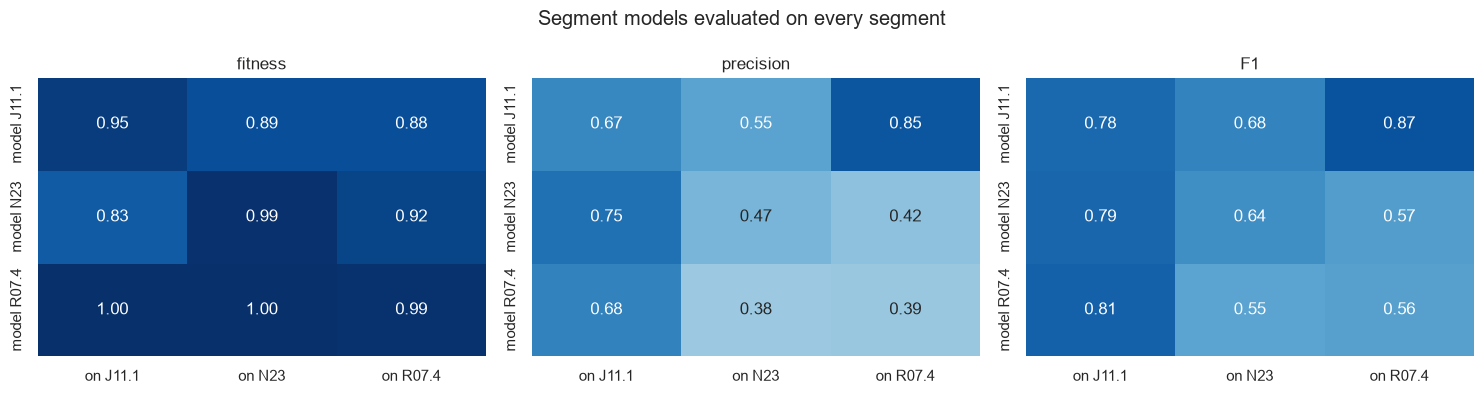

In [75]:
names = list(segment_logs)
cross = {metric: pd.DataFrame(index=[f"model {n}" for n in names],
                              columns=[f"on {n}" for n in names], dtype=float)
         for metric in ["fitness", "precision", "F1"]}
for m in names:
    for s in names:
        result = score_model(discovered[f"M2 {m}"], segment_logs[s])
        for metric in cross:
            cross[metric].loc[f"model {m}", f"on {s}"] = result[metric]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (metric, table) in zip(axes, cross.items()):
    sns.heatmap(table, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=ax)
    ax.set_title(metric)
fig.suptitle("Segment models evaluated on every segment")
plt.tight_layout()
plt.show()

### Noise threshold 

The inductive miner's noise threshold decides how much infrequent behaviour is dropped. We discover the merged model (M1) with several thresholds and score each on the reference log, with token-based replay **and** with alignments. Token-based replay is known to be optimistic, so the alignment-based scores are the ones used to choose.

,size (P+T),simplicity,fitness,precision,F1,fitness (align),precision (align),F1 (align)
noise,,,,,,,,
0.0,75.0,0.641,1.000,0.517,0.681,1.000,0.517,0.681
0.1,56.0,0.667,0.993,0.545,0.704,0.986,0.548,0.705
0.2,42.0,0.677,0.934,0.793,0.858,0.881,0.793,0.835
0.3,41.0,0.695,0.933,0.795,0.858,0.878,0.795,0.834
0.4,48.0,0.706,0.956,0.888,0.921,0.794,0.888,0.838


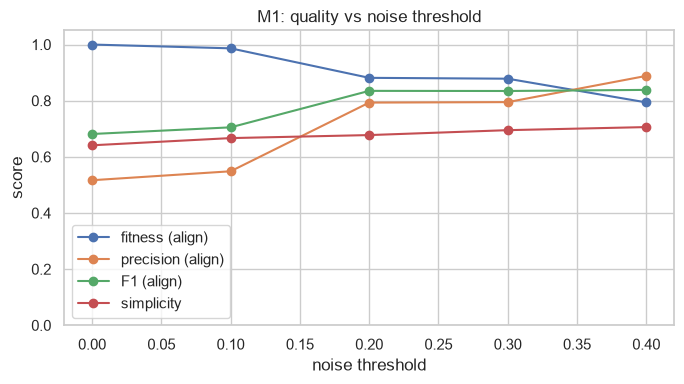

In [76]:
def score_alignments(model, eval_log):
    net, im, fm = model
    fitness = pm4py.fitness_alignments(core(eval_log), net, im, fm)["log_fitness"]
    precision = pm4py.precision_alignments(core(eval_log), net, im, fm)
    return {"fitness (align)": fitness, "precision (align)": precision, "F1 (align)": f1_score(fitness, precision)}

sweep_rows = {}
for noise in [0.0, 0.1, 0.2, 0.3, 0.4]:
    model = discover(reference_log, noise)
    discovered[f"M1 noise={noise}"] = model
    sweep_rows[noise] = {**score_model(model, reference_log), **score_alignments(model, reference_log)}
sweep = pd.DataFrame(sweep_rows).T
sweep.index.name = "noise"
display(sweep[["size (P+T)", "simplicity", "fitness", "precision", "F1", "fitness (align)", "precision (align)", "F1 (align)"]].round(3))

fig, ax = plt.subplots(figsize=(7, 4))
for metric in ["fitness (align)", "precision (align)", "F1 (align)", "simplicity"]:
    ax.plot(sweep.index, sweep[metric], marker="o", label=metric)
ax.set(xlabel="noise threshold", ylabel="score", title="M1: quality vs noise threshold", ylim=(0, 1.05))
ax.legend()
plt.tight_layout()
plt.show()

### Model selection

We pick the threshold with the highest **alignment-based F1** and, as a tie-break, the simpler model. The selected model is then drawn.

Selected model: M1 noise=0.4


,fitness (align),precision (align),F1 (align),simplicity,size (P+T)
noise,,,,,
0.4,0.794,0.888,0.838,0.706,48.0


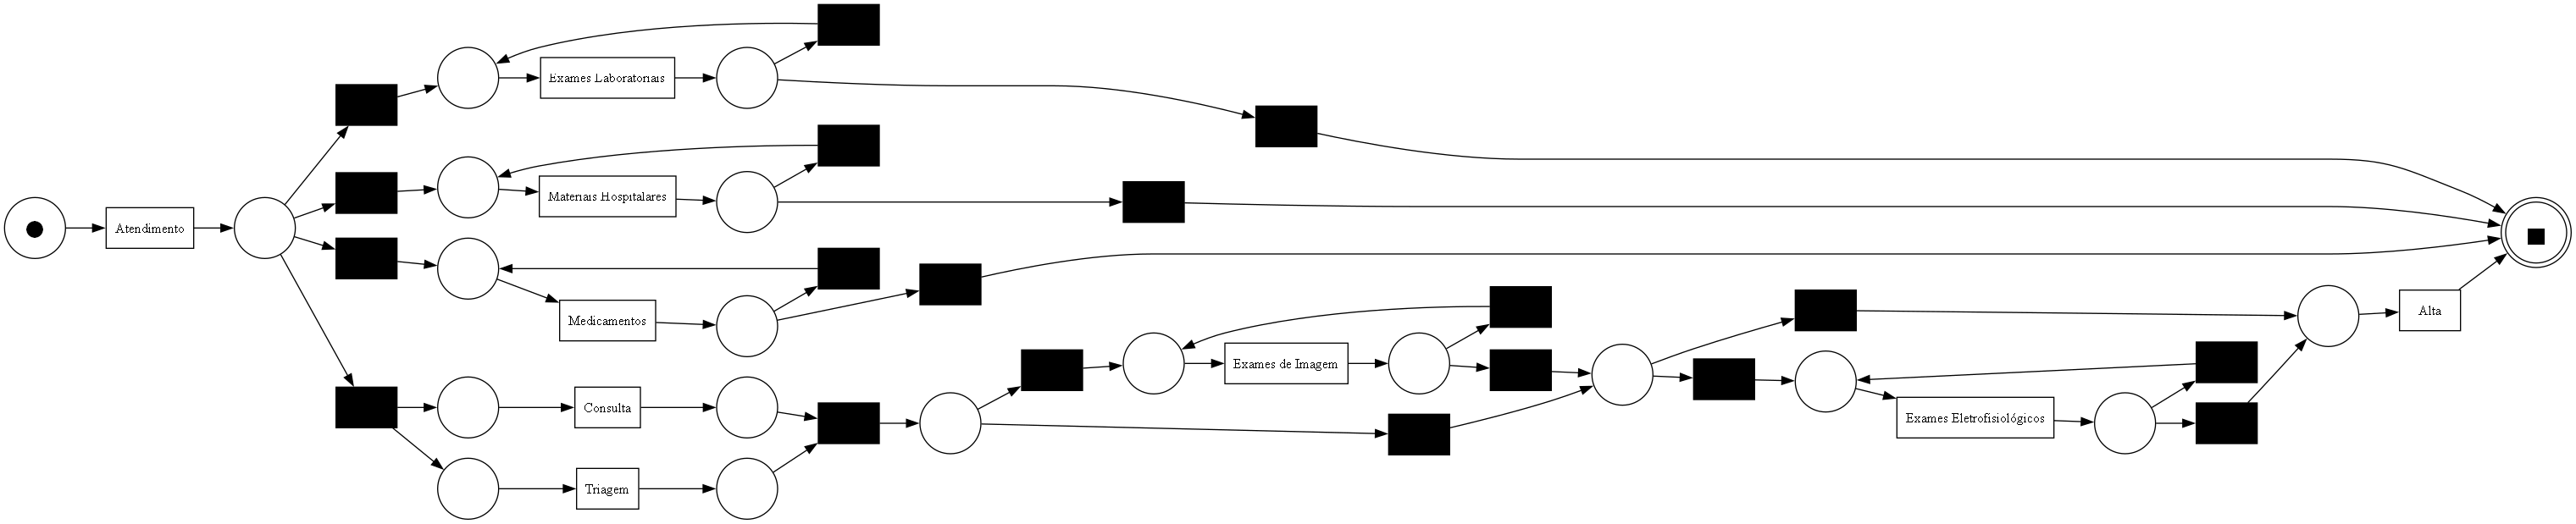

In [77]:
candidates = sweep.sort_values(["F1 (align)", "simplicity"], ascending=False)
best_noise = candidates.index[0]
selected_name = f"M1 noise={best_noise}"
selected_model = discovered[selected_name]
print(f"Selected model: {selected_name}")
display(sweep.loc[[best_noise], ["fitness (align)", "precision (align)", "F1 (align)", "simplicity", "size (P+T)"]].round(3))

net, im, fm = selected_model
pm4py.view_petri_net(net, im, fm, format="png")

## Conformance checking and outliers

A model is the reference for "normal" behaviour: a case that does not fit it is a *structural* deviation. `outlier_label` is a pre-computed label based on case duration, so comparing the two tells us whether structural deviations (what the model sees) coincide with temporal outliers (what the label sees).

We run conformance with **two reference models** and compare them:

* **merged**: the selected M1 model, applied to all the cases;
* **segment-specific**: the model of each diagnosis (M2), applied only to the cases of that diagnosis.

For each case we compute an alignment and keep its **fitness** (1 = the case follows the model) and its **number of deviating moves** (activities skipped, or not expected by the model).

In [ ]:
def deviating_moves(alignment):
    # log move: an event the model does not allow here; model move: an activity the model requires but the case skipped
    return sum(1 for log_label, model_label in alignment["alignment"]
               if (log_label == ">>" and model_label is not None) or (model_label == ">>"))

def case_conformance(model, eval_log):
    net, im, fm = model
    alignments = pm4py.conformance_diagnostics_alignments(core(eval_log), net, im, fm)
    case_ids = eval_log.groupby(case_column, sort=False).size().index     
    result = pd.DataFrame({
        case_column: case_ids,
        "alignment_fitness": [a["fitness"] for a in alignments],
        "deviating_moves": [deviating_moves(a) for a in alignments],
    }).set_index(case_column)
    result["deviating"] = result["alignment_fitness"] < 1.0
    return result

info = reference_log.groupby(case_column).agg(
    disease=(disease_column, "first"), outlier_label=("outlier_label", "first"))
info["duration_hours"] = comparison_cases.loc[info.index, "duration_hours"]

conf_merged = case_conformance(selected_model, reference_log).join(info)
conf_segment = pd.concat([
    case_conformance(discovered[f"M2 {short_name[d]}"], main_disease_segments[d]) for d in main_diseases
]).join(info)
conformance_results = {"merged model (M1)": conf_merged, "segment models (M2)": conf_segment}

,deviating cases,deviating %,labelled outliers,outliers flagged (recall %),flagged that are outliers (precision %)
merged model (M1),125.0,29.762,20.0,75.0,12.000
segment models (M2),115.0,27.381,20.0,55.0,9.565


Share of cases flagged as deviating, by diagnosis:


,merged model (M1),segment models (M2),labelled outliers %
disease,,,
J11.1 Influenza c/out manif resp dev virus n ident,19.0,30.3,3.2
N23 Colica nefretica NE,95.3,11.6,2.3
R07.4 Dor toracica NE,60.0,16.7,26.7


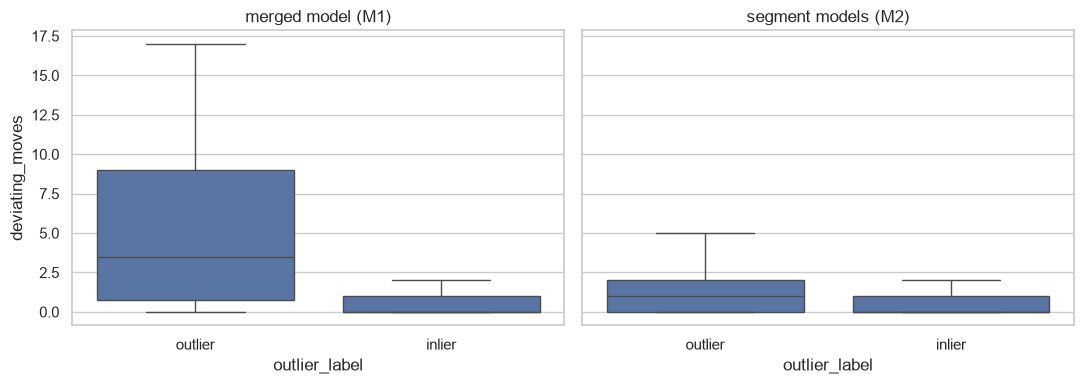

In [85]:
from scipy import stats

def cliffs_delta(a, b):
    a, b = np.asarray(a), np.asarray(b)
    return (np.count_nonzero(a[:, None] > b[None, :]) - np.count_nonzero(a[:, None] < b[None, :])) / (len(a) * len(b))

summary_rows = {}
for name, table in conformance_results.items():
    is_out = table["outlier_label"] == "outlier"
    flagged = table["deviating"]
    out_moves, in_moves = table.loc[is_out, "deviating_moves"], table.loc[~is_out, "deviating_moves"]
    summary_rows[name] = {
        "deviating cases": int(flagged.sum()),
        "deviating %": 100 * flagged.mean(),
        "labelled outliers": int(is_out.sum()),
        "outliers flagged (recall %)": 100 * (flagged & is_out).sum() / is_out.sum(),
        "flagged that are outliers (precision %)": 100 * (flagged & is_out).sum() / flagged.sum(),
    }
display(pd.DataFrame(summary_rows).T.round(3))

print("Share of cases flagged as deviating, by diagnosis:")
display(pd.DataFrame({
    name: table.groupby("disease")["deviating"].mean() * 100 for name, table in conformance_results.items()
}).assign(**{"labelled outliers %": conf_merged.groupby("disease")["outlier_label"].apply(lambda s: 100 * (s == "outlier").mean())}).round(1))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (name, table) in zip(axes, conformance_results.items()):
    sns.boxplot(data=table, x="outlier_label", y="deviating_moves", showfliers=False, ax=ax)
    ax.set_title(name)
plt.tight_layout()
plt.show()

# 6 - Improvement Proposals

The proposals below are built on evidence already produced in sections 3-5; they regard **segment profiles**, **rework** and **case-size tests**, **discovered models** and **conformance results**.

### Proposal 1 - Reduce repeated procedures

Within every diagnosis, cases with repeated procedures (consultations, laboratory tests or imaging) last longer than the others, and the differences are significant. Repeated procedures can be reduced by grouping the laboratory and imaging requests of a case into a single complete request, and by a checklist before a new request is issued. This is an association: a case that is already long has more opportunities to repeat a test, so the data do not prove that repetitions *cause* the longer stay.

### Proposal 2 - Automatic registration for influenza

Influenza is the large majority of the cases, has the shortest cases (median 4 events) and one dominant path (Atendimento, Triagem, Consulta, Alta). This predictability makes it the natural candidate for automating the registration and triage data capture and for a short protocol-based pathway. The log does not measure how long registration and triage take, so the benefit of this proposal is plausible but not quantified.